In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.datasets import fetch_california_housing

In [3]:
X,y=fetch_california_housing(return_X_y=True,as_frame=True)

In [86]:
fetch_california_housing().feature_names

['MedInc',
 'HouseAge',
 'AveRooms',
 'AveBedrms',
 'Population',
 'AveOccup',
 'Latitude',
 'Longitude']

In [9]:
df=pd.DataFrame(fetch_california_housing().data,columns=fetch_california_housing().feature_names)
df['MEDV']=y

In [10]:
df

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MEDV
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
...,...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847


In [11]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [48]:
tree_regressor=DecisionTreeRegressor()

In [60]:
params={'max_depth':[2,4,6,8,10],'criterion':['squared_error','absolute_error'],'min_samples_split':[0.5,1.0],'max_features':[0.5,1.0]}

In [61]:
reg=GridSearchCV(tree_regressor,params,cv=5,scoring='r2',verbose=3)
reg.fit(X_train,y_train)

Fitting 5 folds for each of 40 candidates, totalling 200 fits
[CV 1/5] END criterion=squared_error, max_depth=2, max_features=0.5, min_samples_split=0.5;, score=0.189 total time=   0.0s
[CV 2/5] END criterion=squared_error, max_depth=2, max_features=0.5, min_samples_split=0.5;, score=0.190 total time=   0.0s
[CV 3/5] END criterion=squared_error, max_depth=2, max_features=0.5, min_samples_split=0.5;, score=0.340 total time=   0.0s
[CV 4/5] END criterion=squared_error, max_depth=2, max_features=0.5, min_samples_split=0.5;, score=0.233 total time=   0.0s
[CV 5/5] END criterion=squared_error, max_depth=2, max_features=0.5, min_samples_split=0.5;, score=0.358 total time=   0.0s
[CV 1/5] END criterion=squared_error, max_depth=2, max_features=0.5, min_samples_split=1.0;, score=0.324 total time=   0.0s
[CV 2/5] END criterion=squared_error, max_depth=2, max_features=0.5, min_samples_split=1.0;, score=0.319 total time=   0.0s
[CV 3/5] END criterion=squared_error, max_depth=2, max_features=0.5, m

GridSearchCV(cv=5, estimator=DecisionTreeRegressor(),
             param_grid={'criterion': ['squared_error', 'absolute_error'],
                         'max_depth': [2, 4, 6, 8, 10],
                         'max_features': [0.5, 1.0],
                         'min_samples_split': [0.5, 1.0]},
             scoring='r2', verbose=3)

In [63]:
reg.best_score_

np.float64(0.3906376997295793)

In [68]:
default_param_grid = {k: [v] for k, v in tree_regressor.get_params().items()}
rt=GridSearchCV(tree_regressor,param_grid=default_param_grid,cv=10,scoring='r2',verbose=3)
rt.fit(X_train,y_train)

Fitting 10 folds for each of 1 candidates, totalling 10 fits
[CV 1/10] END ccp_alpha=0.0, criterion=squared_error, max_depth=None, max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.0, min_samples_leaf=1, min_samples_split=2, min_weight_fraction_leaf=0.0, monotonic_cst=None, random_state=None, splitter=best;, score=0.621 total time=   0.3s
[CV 2/10] END ccp_alpha=0.0, criterion=squared_error, max_depth=None, max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.0, min_samples_leaf=1, min_samples_split=2, min_weight_fraction_leaf=0.0, monotonic_cst=None, random_state=None, splitter=best;, score=0.591 total time=   0.3s
[CV 3/10] END ccp_alpha=0.0, criterion=squared_error, max_depth=None, max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.0, min_samples_leaf=1, min_samples_split=2, min_weight_fraction_leaf=0.0, monotonic_cst=None, random_state=None, splitter=best;, score=0.647 total time=   0.3s
[CV 4/10] END ccp_alpha=0.0, criterion=squared_error, max

GridSearchCV(cv=10, estimator=DecisionTreeRegressor(),
             param_grid={'ccp_alpha': [0.0], 'criterion': ['squared_error'],
                         'max_depth': [None], 'max_features': [None],
                         'max_leaf_nodes': [None],
                         'min_impurity_decrease': [0.0],
                         'min_samples_leaf': [1], 'min_samples_split': [2],
                         'min_weight_fraction_leaf': [0.0],
                         'monotonic_cst': [None], 'random_state': [None],
                         'splitter': ['best']},
             scoring='r2', verbose=3)

In [70]:
rt.best_params_

{'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'random_state': None,
 'splitter': 'best'}

[Text(0.6, 0.8333333333333334, 'x[0] <= 5.086\nsquared_error = 1.337\nsamples = 16512\nvalue = 2.072'),
 Text(0.4, 0.5, 'x[0] <= 3.074\nsquared_error = 0.834\nsamples = 13101\nvalue = 1.74'),
 Text(0.5, 0.6666666666666667, 'True  '),
 Text(0.2, 0.16666666666666666, 'squared_error = 0.561\nsamples = 6268\nvalue = 1.358'),
 Text(0.6, 0.16666666666666666, 'squared_error = 0.827\nsamples = 6833\nvalue = 2.09'),
 Text(0.8, 0.5, 'squared_error = 1.218\nsamples = 3411\nvalue = 3.348'),
 Text(0.7, 0.6666666666666667, '  False')]

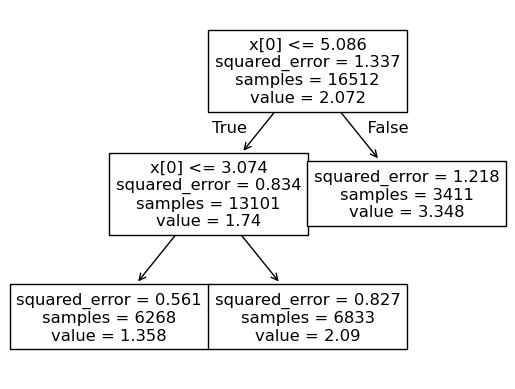

In [73]:
from sklearn.tree import plot_tree
plot_tree(reg.best_estimator_)

In [74]:
!pip install dtreeviz

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.3/102.3 kB 4.5 MB/s eta 0:00:00


In [80]:
import graphviz.backend as be
import dtreeviz as dt

In [76]:
from IPython.display import Image,display_svg,SVG

In [89]:
m = dt.model(reg.best_estimator_,
             X_train=X_train, y_train=y_train,
             feature_names=fetch_california_housing().feature_names,
             target_name="MEDV"
            )
viz = m.view(scale=2)
viz

Output hidden; open in https://colab.research.google.com to view.